# Predicting Annual Wages of Full-Time Workers in Texas
### Machine Learning and Data Analytics (6COSC017C) — Coursework 1
**Student ID:** 00017665

**Data:** American Community Survey (ACS) 2024 1-Year Public Use Microdata Sample (PUMS), Texas person file — U.S. Census Bureau (public domain).
**Task:** supervised **regression** — predict a full-time employee's annual wage (`WAGP`) from education, occupation, industry, job and demographic characteristics.

**Contents**
1. Data loading and instance selection
2. Exploratory Data Analysis (EDA)
3. Data preparation
4. Model training *(next milestone)*
5. Model evaluation *(next milestone)*

## 0. Setup
All libraries are pinned in `pyproject.toml` / `uv.lock`, so the notebook can be reproduced with `uv sync`.
A fixed random seed is used everywhere randomness appears.

In [62]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Project paths (the notebook lives in notebooks/, data in data/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_FILE = ROOT / "data" / "raw" / "psam_p48.csv"
PROCESSED_FILE = ROOT / "data" / "processed" / "acs_tx_2024_fulltime.csv"

# Helper module with the decoding tables for the PUMS numeric codes
sys.path.append(str(ROOT / "src"))
from mlda_cw1 import codes

RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)   # 2 decimals, thousands separator

# Chart style: seaborn's clean theme + two colours used throughout the notebook
sns.set_theme(style="whitegrid")
BLUE, ORANGE = "#2a78d6", "#eb6834"

## 1. Data loading and instance selection

### 1.1 Source
The ACS is the largest household survey in the United States (~1% of the population each year).
The PUMS file contains **one row per person** with anonymised answers to the questionnaire.
We use the 2024 Texas person-level file, downloaded from
<https://www2.census.gov/programs-surveys/acs/data/pums/2024/1-Year/> (`csv_ptx.zip` → `psam_p48.csv`).
Texas was chosen because it is the second-largest state with a diverse economy (energy, technology, healthcare, agriculture), giving a large and varied sample.

### 1.2 Which columns are loaded and why
The raw file has 286 columns; most are irrelevant (housing allocation flags, 80 replicate weights, etc.).
We load only the variables that plausibly explain wages **and are known before the wage is observed**:

| Group | Variables | Meaning |
|---|---|---|
| Identifiers | `SERIALNO`, `SPORDER` | household id + person number (unique person key) |
| Target | `WAGP` | wages or salary income in the past 12 months (USD) |
| Adjustment | `ADJINC` | factor that converts income to 2024 dollars |
| Weight | `PWGTP` | person weight (how many people each row represents) |
| Human capital | `AGEP`, `SCHL`, `FOD1P` | age, educational attainment, field of bachelor's degree |
| Job | `OCCP`, `INDP`, `COW`, `WKHP`, `WKWN` | occupation, industry, class of worker, usual hours/week, weeks worked |
| Commute | `JWMNP`, `JWTRNS` | travel time to work (min), means of transport |
| Demographics | `SEX`, `MAR`, `RAC1P`, `HISP`, `NATIVITY`, `ENG`, `DIS`, `MIL` | used for EDA and fairness checks |
| Geography | `PUMA` | Public Use Microdata Area (~217 regions in Texas) |
| Filter only | `ESR` | employment status |

**Deliberately excluded — target leakage:** `PERNP` (total earnings) and `PINCP` (total income) *contain* `WAGP`, so using them would let the model "see the answer".

In [63]:
LOAD_COLS = [
    "SERIALNO", "SPORDER", "PUMA", "ADJINC", "PWGTP",
    "AGEP", "SEX", "SCHL", "FOD1P", "MAR", "RAC1P", "HISP", "NATIVITY", "ENG", "DIS", "MIL",
    "COW", "ESR", "OCCP", "INDP", "WKHP", "WKWN", "JWMNP", "JWTRNS",
    "WAGP",
]

if RAW_FILE.exists():
    raw_columns = pd.read_csv(RAW_FILE, nrows=0).columns        # header only -> total column count
    raw = pd.read_csv(RAW_FILE, usecols=LOAD_COLS, low_memory=False)
    print(f"Raw file: {len(raw):,} rows x {len(raw_columns)} columns "
          f"-> loaded {raw.shape[1]} selected columns")
else:
    raw = None
    print("Raw file not found - the processed dataset will be loaded in step 1.4.")

Raw file: 292,272 rows x 286 columns -> loaded 25 selected columns


### 1.3 Instance selection (filtering the population)
The research question is about **wages of full-time employees**, so rows outside that population are removed.
Each condition has a clear reason:

| Condition | Reason |
|---|---|
| `AGEP` 18–64 | working-age adults; excludes children and most retirees |
| `ESR` ∈ {1, 2} | civilian employed (at work / with a job but not at work) |
| `COW` ∈ {1…5} | employees of private firms or government; the self-employed earn *business income*, not wages |
| `WKHP` ≥ 35 | full-time (U.S. Bureau of Labor Statistics definition) — removes part-time effects |
| `WAGP` > 0 | a wage must exist to be predicted |

The table below is a **filtering funnel**: it shows how many people remain after each step.
(The last condition removes no extra rows, because every full-time employee in the file reported a wage, but it is kept as a safeguard.)

In [64]:
if raw is not None:
    steps = [
        ("All persons in file",             pd.Series(True, index=raw.index)),
        ("Age 18-64",                       raw["AGEP"].between(18, 64)),
        ("Civilian employed (ESR 1-2)",     raw["ESR"].isin([1, 2])),
        ("Employee, not self-employed",     raw["COW"].between(1, 5)),
        ("Full-time (35+ hours/week)",      raw["WKHP"] >= 35),
        ("Positive wage income",            raw["WAGP"] > 0),
    ]
    mask = pd.Series(True, index=raw.index)
    funnel = []
    for name, condition in steps:
        mask &= condition                                     # conditions are applied cumulatively
        funnel.append((name, int(mask.sum())))
    funnel = pd.DataFrame(funnel, columns=["Step", "Rows remaining"])
    funnel["% of file"] = funnel["Rows remaining"] / len(raw) * 100
    display(funnel)

    df = raw.loc[mask].drop(columns=["ESR"]).reset_index(drop=True)   # ESR is constant after filtering

,Step,Rows remaining,% of file
0,All persons in file,292272,100.00
1,Age 18-64,171498,58.68
2,Civilian employed (ESR 1-2),121832,41.68
3,"Employee, not self-employed",109092,37.33
4,Full-time (35+ hours/week),92513,31.65
5,Positive wage income,92513,31.65


### 1.4 Saving the working dataset
The filtered file (~92 thousand rows, 24 columns) is small enough for GitHub, the Streamlit app and the submission zip,
while the 206 MB raw file stays local (it is listed in `.gitignore`).
If the raw file is absent, the notebook simply loads this saved dataset, so every later step is reproducible.

In [65]:
if raw is not None:
    PROCESSED_FILE.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(PROCESSED_FILE, index=False)
    print(f"Saved {PROCESSED_FILE.name}: {df.shape[0]:,} rows x {df.shape[1]} columns, "
          f"{PROCESSED_FILE.stat().st_size / 1e6:.1f} MB")
    del raw                                                   # free memory
else:
    df = pd.read_csv(PROCESSED_FILE)
    print(f"Loaded {PROCESSED_FILE.name}: {df.shape[0]:,} rows x {df.shape[1]} columns")

df.head()

Saved acs_tx_2024_fulltime.csv: 92,513 rows x 24 columns, 9.9 MB


,SERIALNO,SPORDER,PUMA,ADJINC,PWGTP,AGEP,COW,ENG,JWMNP,JWTRNS,MAR,MIL,SCHL,SEX,WAGP,WKHP,WKWN,DIS,FOD1P,HISP,INDP,NATIVITY,OCCP,RAC1P
0,2024GQ0000017,1,2600,1015250,8,43,1.00,NaN,10.00,1.00,5,4.00,17.00,2,"5,300.00",40.00,16.00,2,NaN,1,"8,680.00",1,310.00,2
1,2024GQ0000079,1,2503,1015250,49,36,1.00,NaN,3.00,1.00,5,4.00,22.00,2,"46,500.00",40.00,52.00,2,"3,600.00",1,"7,071.00",1,"4,640.00",2
2,2024GQ0000958,1,4503,1015250,13,52,1.00,NaN,NaN,11.00,3,2.00,16.00,1,"30,000.00",40.00,52.00,1,NaN,1,"8,380.00",1,"4,220.00",1
3,2024GQ0001936,1,6000,1015250,53,22,1.00,NaN,5.00,10.00,5,4.00,21.00,1,"34,800.00",40.00,52.00,2,"6,203.00",1,"7,071.00",1,"5,940.00",2
4,2024GQ0002576,1,300,1015250,20,19,4.00,NaN,8.00,8.00,5,4.00,19.00,2,"15,000.00",35.00,52.00,2,NaN,1,"7,870.00",1,"2,205.00",1


### 1.5 Data type conversion
Code columns that contain blanks are read by pandas as decimals (`float`, e.g. occupation `4640.0`), because the classic integer type cannot store a missing value.
They are converted to pandas' **nullable integer** type `Int64`, which keeps whole numbers and still allows missing values (`<NA>`).

In [66]:
INT_COLS = ["COW", "ENG", "JWMNP", "JWTRNS", "MAR", "MIL", "SCHL", "WKHP", "WKWN",
            "FOD1P", "INDP", "OCCP"]
df[INT_COLS] = df[INT_COLS].astype("Int64")
df["WAGP"] = df["WAGP"].astype(float)          # target stays a continuous number
df.head()

,SERIALNO,SPORDER,PUMA,ADJINC,PWGTP,AGEP,COW,ENG,JWMNP,JWTRNS,MAR,MIL,SCHL,SEX,WAGP,WKHP,WKWN,DIS,FOD1P,HISP,INDP,NATIVITY,OCCP,RAC1P
0,2024GQ0000017,1,2600,1015250,8,43,1,<NA>,10,1,5,4,17,2,"5,300.00",40,16,2,<NA>,1,8680,1,310,2
1,2024GQ0000079,1,2503,1015250,49,36,1,<NA>,3,1,5,4,22,2,"46,500.00",40,52,2,3600,1,7071,1,4640,2
2,2024GQ0000958,1,4503,1015250,13,52,1,<NA>,<NA>,11,3,2,16,1,"30,000.00",40,52,1,<NA>,1,8380,1,4220,1
3,2024GQ0001936,1,6000,1015250,53,22,1,<NA>,5,10,5,4,21,1,"34,800.00",40,52,2,6203,1,7071,1,5940,2
4,2024GQ0002576,1,300,1015250,20,19,4,<NA>,8,8,5,4,19,2,"15,000.00",35,52,2,<NA>,1,7870,1,2205,1


## 2. Exploratory Data Analysis
EDA answers four questions before any modelling: *what does the data look like, how clean is it,
how is the target distributed, and which variables are related to it?* Each finding below feeds a concrete decision in Section 3.

### 2.1 Structure and variable types

In [67]:
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns\n")
print(df.dtypes.value_counts().to_string())

Shape: 92,513 rows x 24 columns

Int64      12
int64      10
str         1
float64     1


All columns except the id `SERIALNO` are stored as **numbers**, but most of them are actually **categories encoded as numbers**
(e.g. `SEX` 1 = male, 2 = female; `OCCP` 2205 = postsecondary teachers). Treating these codes as quantities would be meaningless
(occupation 2205 is not "more" than 1005), so each variable is assigned its true statistical type:

In [68]:
var_types = pd.DataFrame({
    "variable": ["WAGP", "AGEP", "WKHP", "WKWN", "JWMNP",
                 "SCHL", "ENG",
                 "SEX", "NATIVITY", "DIS",
                 "OCCP", "INDP", "COW", "MAR", "RAC1P", "HISP", "MIL", "JWTRNS", "FOD1P", "PUMA",
                 "SERIALNO", "SPORDER", "PWGTP", "ADJINC"],
    "type": ["numerical (continuous) - TARGET", "numerical (discrete)", "numerical (discrete)",
             "numerical (discrete)", "numerical (discrete)",
             "categorical (ordinal)", "categorical (ordinal)",
             "categorical (binary)", "categorical (binary)", "categorical (binary)"]
            + ["categorical (nominal)"] * 10
            + ["identifier", "identifier", "survey weight", "constant adjustment factor"],
})
var_types.groupby("type")["variable"].apply(", ".join).to_frame()

,variable
type,
categorical (binary),"SEX, NATIVITY, DIS"
categorical (nominal),"OCCP, INDP, COW, MAR, RAC1P, HISP, MIL, JWTRNS..."
categorical (ordinal),"SCHL, ENG"
constant adjustment factor,ADJINC
identifier,"SERIALNO, SPORDER"
numerical (continuous) - TARGET,WAGP
numerical (discrete),"AGEP, WKHP, WKWN, JWMNP"
survey weight,PWGTP


To make the analysis readable, the codes are **decoded** into labels using the official PUMS data dictionary
(see `src/mlda_cw1/codes.py`). Detailed occupation (~520 codes) and industry (~250 codes) are grouped into
the Census major groups (25 and 17). These label columns are used for EDA only; the formal encoding is done in Section 3.

In [69]:
eda = df.copy()
eda["log_wage"]   = np.log(eda["WAGP"])                  # log of the target (justified in 2.5)
eda["sex"]        = eda["SEX"].map(codes.SEX)
eda["education"]  = codes.edu_level(eda["SCHL"])
eda["occupation"] = codes.occupation_group(eda["OCCP"])
eda["industry"]   = codes.industry_sector(eda["INDP"])
eda["employer"]   = eda["COW"].map(codes.COW)
eda["marital"]    = eda["MAR"].map(codes.MAR)
eda["nativity"]   = eda["NATIVITY"].map(codes.NATIVITY)
eda["race_eth"]   = codes.race_ethnicity(eda["RAC1P"], eda["HISP"])
eda["disability"] = eda["DIS"].map(codes.DIS)
eda["military"]   = eda["MIL"].map(codes.MIL)
eda["transport"]  = eda["JWTRNS"].map(codes.JWTRNS)
eda[["WAGP", "sex", "education", "occupation", "industry", "employer"]].head()

,WAGP,sex,education,occupation,industry,employer
0,"5,300.00",Female,HS diploma / GED,Management,"Arts, accommodation & food",Private for-profit
1,"46,500.00",Female,Master's,Personal care,"Finance, insurance & real estate",Private for-profit
2,"30,000.00",Male,HS diploma / GED,Cleaning & maintenance,Health care & social assistance,Private for-profit
3,"34,800.00",Male,Bachelor's,Office & admin support,"Finance, insurance & real estate",Private for-profit
4,"15,000.00",Female,Some college,Education,Education,State government


### 2.2 Missing values and duplicates
Missing data must be understood *before* it is treated: values can be missing at random, or missing **for a structural reason**
that itself carries information.

,missing,pct
ENG,61363,66.33
FOD1P,52809,57.08
JWMNP,13269,14.34
JWTRNS,1066,1.15


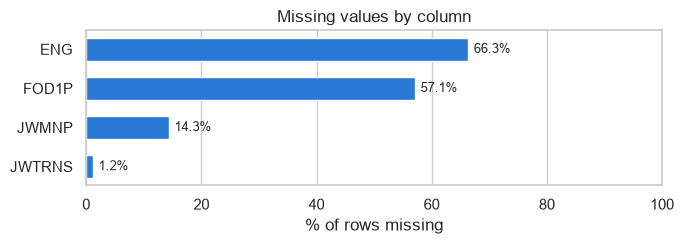

In [70]:
missing = pd.DataFrame({"missing": df.isna().sum()})
missing["pct"] = missing["missing"] / len(df) * 100
missing = missing[missing["missing"] > 0].sort_values("pct", ascending=False)
display(missing)

fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh(missing.index[::-1], missing["pct"][::-1], color=BLUE, height=0.6)
for y, v in enumerate(missing["pct"][::-1]):
    ax.text(v + 1, y, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlim(0, 100); ax.set_xlabel("% of rows missing"); ax.grid(axis="y", visible=False)
ax.set_title("Missing values by column")
plt.tight_layout(); plt.show()

In [71]:
# Why are values missing? Cross-check each column against the variable that explains it.
print("FOD1P missing vs. education (field of degree exists only for bachelor's or higher):")
display(pd.crosstab(eda["education"], eda["FOD1P"].isna(), normalize="index").round(3)
          .rename(columns={False: "has FOD1P", True: "FOD1P missing"}))

print("\nJWMNP (commute time) missing vs. means of transport:")
transport = eda["transport"].fillna("Not at work last week")
display(pd.crosstab(transport, eda["JWMNP"].isna())
          .rename(columns={False: "has JWMNP", True: "JWMNP missing"})
          .sort_values("has JWMNP", ascending=False).head(6))

print(f"\nENG missing: {df['ENG'].isna().mean():.1%} -> in PUMS 'not applicable' means the person speaks only English at home")

FOD1P missing vs. education (field of degree exists only for bachelor's or higher):


FOD1P,has FOD1P,FOD1P missing
education,,
Less than HS,0.00,1.00
HS diploma / GED,0.00,1.00
Some college,0.00,1.00
Associate's,0.00,1.00
Bachelor's,1.00,0.00
Master's,1.00,0.00
Professional,1.00,0.00
Doctorate,1.00,0.00



JWMNP (commute time) missing vs. means of transport:


JWMNP,has JWMNP,JWMNP missing
transport,,
"Car, truck or van",76096,0
Walked,1044,0
Other,870,0
Bus,584,0
Taxicab,249,0
Bicycle,165,0



ENG missing: 66.3% -> in PUMS 'not applicable' means the person speaks only English at home


**Finding:** none of the missing values are random errors — all are **structurally missing**:

* `ENG` (66%) is blank for people who speak **only English** → it will become a category "Only English", not be imputed.
* `FOD1P` (57%) is blank for everyone **without a bachelor's degree** → new category "No degree".
* `JWMNP` (14%) is blank for people who **work from home** or were **not at work** that week → commute time 0 / separate flag.
* `JWTRNS` (1%) is blank for those **not at work last week** → category "Not at work".

Dropping these rows would delete two-thirds of the data and bias the sample, so in Section 3 they are filled with meaningful values.

In [72]:
dup_people = df.duplicated(subset=["SERIALNO", "SPORDER"]).sum()
dup_rows   = df.drop(columns=["SERIALNO", "SPORDER"]).duplicated().sum()
print(f"Duplicate person keys (SERIALNO + SPORDER): {dup_people}")
print(f"Rows identical in every other column:       {dup_rows}")

Duplicate person keys (SERIALNO + SPORDER): 0
Rows identical in every other column:       3


There are no duplicated persons. The few rows that coincide on every attribute belong to **different people**
(different household/person ids) who happen to share the same coded answers — they are genuine observations and are kept.

### 2.3 Summary statistics — numerical variables
Measures of **central tendency** (mean, median) and **dispersion** (variance, standard deviation, IQR) describe each variable;
**skewness** and **kurtosis** describe the shape. Comparing mean and median is a quick test for skew: if mean ≫ median, the
distribution has a long right tail.

In [73]:
num_cols = ["WAGP", "AGEP", "WKHP", "WKWN", "JWMNP"]
summary = df[num_cols].describe().T
summary["variance"] = df[num_cols].var()
summary["IQR"]      = summary["75%"] - summary["25%"]
summary["skewness"] = df[num_cols].skew()
summary["kurtosis"] = df[num_cols].kurt()
summary = summary[["count", "mean", "50%", "std", "variance", "min", "25%", "75%", "max",
                   "IQR", "skewness", "kurtosis"]].rename(columns={"50%": "median"})
summary

,count,mean,median,std,variance,min,25%,75%,max,IQR,skewness,kurtosis
WAGP,"92,513.00","79,207.96","60,000.00","82,277.04","6,769,511,256.19",50.00,"35,000.00","95,000.00","601,000.00","60,000.00",3.90,20.25
AGEP,"92,513.00",41.85,42.00,12.28,150.87,18.00,32.00,52.00,64.00,20.00,0.03,-1.10
WKHP,"92,513.00",43.77,40.00,8.27,68.39,35.00,40.00,45.00,99.00,5.00,2.78,9.98
WKWN,"92,513.00",50.26,52.00,7.12,50.66,1.00,52.00,52.00,52.00,0.00,-4.81,23.88
JWMNP,"79,244.00",28.41,22.00,23.22,538.94,1.00,15.00,35.00,153.00,20.00,2.61,10.28


In [74]:
# The survey weight PWGTP says how many Texans each respondent represents.
# Comparing the weighted and unweighted mean checks whether the sample is representative.
weighted_mean = np.average(df["WAGP"], weights=df["PWGTP"])
print(f"Unweighted mean wage: ${df['WAGP'].mean():,.0f}")
print(f"Weighted mean wage:   ${weighted_mean:,.0f}")
print(f"The sample represents {df['PWGTP'].sum():,} full-time employees in Texas")

Unweighted mean wage: $79,208
Weighted mean wage:   $74,416
The sample represents 10,929,197 full-time employees in Texas


**Findings:**
* **Wages** — mean ≈ \$79k but median \$60k; skewness ≈ 3.9 and very high kurtosis → strongly **right-skewed** with a heavy tail of high earners.
* **Hours** — median 40 (the standard full-time week); values up to 99 are rare but possible (e.g. medical residents).
* **Weeks worked** — over 90% worked all 52 weeks; part-year workers will earn less for the same "rate", so `WKWN` is an important predictor.
* The **weighted** mean (using `PWGTP`) is about 6% lower than the unweighted one: the survey slightly over-samples
  higher earners. This matters for estimating *population* averages, but the ML task is to predict an individual's wage *from their characteristics*,
  so the models are trained on unweighted rows (standard ML practice). This is noted as a limitation in the report.

### 2.4 Summary statistics — categorical variables
For categorical variables the relevant statistics are **frequencies** (mode and class balance) and the **median wage per category**,
which gives a first idea of which categories pay more.

In [75]:
def category_profile(col):
    # Count, share and median wage for each category of a column
    g = eda.groupby(col, observed=True)["WAGP"]
    out = pd.DataFrame({"count": g.size(), "share %": g.size() / len(eda) * 100, "median wage": g.median()})
    return out.sort_values("median wage", ascending=False)

for col in ["education", "sex", "employer", "race_eth"]:
    print(f"\n=== {col} ===")
    display(category_profile(col))


=== education ===


,count,share %,median wage
education,,,
Professional,1979,2.14,"135,000.00"
Doctorate,1746,1.89,"105,000.00"
Master's,11080,11.98,"90,000.00"
Bachelor's,24899,26.91,"75,000.00"
Associate's,7593,8.21,"54,000.00"
Some college,17585,19.01,"50,000.00"
HS diploma / GED,20634,22.30,"40,000.00"
Less than HS,6997,7.56,"35,000.00"



=== sex ===


,count,share %,median wage
sex,,,
Male,50299,54.37,"65,000.00"
Female,42214,45.63,"50,000.00"



=== employer ===


,count,share %,median wage
employer,,,
Federal government,2822,3.05,"72,000.00"
State government,4514,4.88,"60,000.00"
Private non-profit,6554,7.08,"60,000.00"
Private for-profit,69183,74.78,"58,000.00"
Local government,9440,10.20,"58,000.00"



=== race_eth ===


,count,share %,median wage
race_eth,,,
Asian (non-Hisp.),6837,7.39,"90,000.00"
White (non-Hisp.),42475,45.91,"70,000.00"
Other (non-Hisp.),3833,4.14,"60,000.00"
Black (non-Hisp.),7570,8.18,"50,000.00"
Hispanic,31798,34.37,"44,000.00"


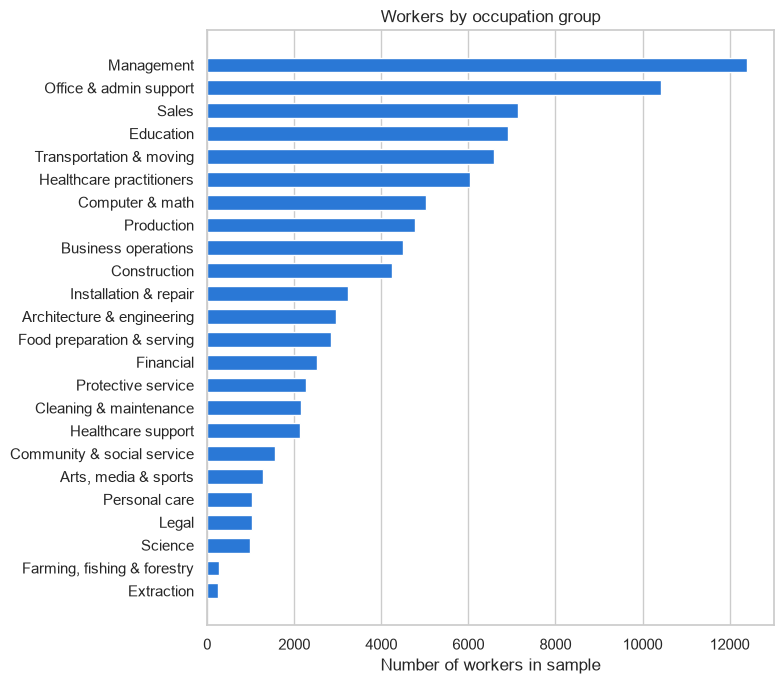

In [76]:
occ = category_profile("occupation").sort_values("count")
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(occ.index, occ["count"], color=BLUE, height=0.65)
ax.set_xlabel("Number of workers in sample"); ax.grid(axis="y", visible=False)
ax.set_title("Workers by occupation group")
plt.tight_layout(); plt.show()

**Findings:** the most common education level is a bachelor's degree, and the sample is 54% male / 46% female.
Occupation groups are **imbalanced** (over 10,000 management and office workers vs. about 250 in extraction or farming) —
rare groups will be handled carefully when encoding, and a stratified split by wage level will keep the test set representative.

### 2.5 Distribution of the target variable
The shape of the target decides the modelling approach. A strongly skewed target makes squared-error models such as Linear Regression
dominated by a few very high earners, so a **log transformation** is tested.

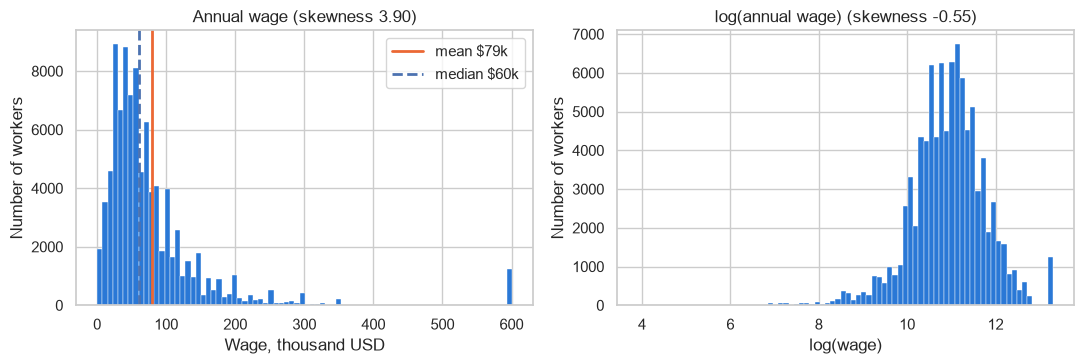

In [77]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(df["WAGP"] / 1000, bins=80, color=BLUE, edgecolor="white", linewidth=0.3)
axes[0].axvline(df["WAGP"].mean() / 1000, color=ORANGE, lw=2, label=f"mean ${df['WAGP'].mean()/1000:,.0f}k")
axes[0].axvline(df["WAGP"].median() / 1000, lw=2, ls="--", label=f"median ${df['WAGP'].median()/1000:,.0f}k")
axes[0].set_title(f"Annual wage (skewness {df['WAGP'].skew():.2f})")
axes[0].set_xlabel("Wage, thousand USD"); axes[0].set_ylabel("Number of workers"); axes[0].legend()

axes[1].hist(eda["log_wage"], bins=80, color=BLUE, edgecolor="white", linewidth=0.3)
axes[1].set_title(f"log(annual wage) (skewness {eda['log_wage'].skew():.2f})")
axes[1].set_xlabel("log(wage)"); axes[1].set_ylabel("Number of workers")
plt.tight_layout(); plt.show()

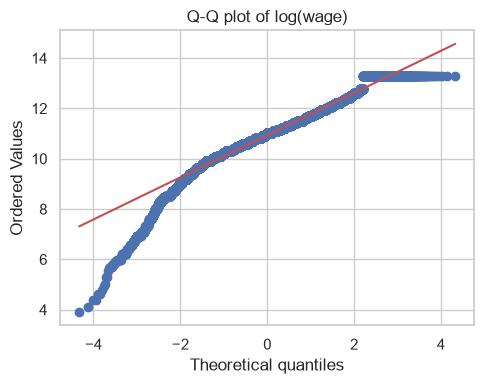

In [78]:
# Q-Q plot: if the log-wage were normal, the points would lie on the straight line
fig, ax = plt.subplots(figsize=(5, 4))
stats.probplot(eda["log_wage"], dist="norm", plot=ax)
ax.set_title("Q-Q plot of log(wage)")
plt.tight_layout(); plt.show()

**Finding:** raw wages are heavily right-skewed (skewness ≈ 3.9). After the log transform the bulk of the distribution is close to normal
(skewness ≈ −0.55) — the Q-Q plot follows the line in the centre. The remaining deviation is a **left tail of implausibly low wages**
and a **flat cap at the top**, examined next. **Decision:** the models will predict `log(WAGP)`; predictions are converted back
to dollars with `exp()` for interpretation.

### 2.6 Outliers and erroneous values
Outliers are checked with the **IQR rule** (outside Q1 − 1.5·IQR … Q3 + 1.5·IQR, applied to log-wage because the raw scale is skewed)
and with **domain logic**. Following the lectures, each outlier is classified as an *error* (to correct/remove) or a *real rare value* (to keep).

In [79]:
q1, q3 = eda["log_wage"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"IQR bounds on log-wage: [{low:.2f}, {high:.2f}]  ->  "
      f"[${np.exp(low):,.0f}, ${np.exp(high):,.0f}]")
print(f"Below lower bound: {(eda['log_wage'] < low).sum():,}   above upper bound: {(eda['log_wage'] > high).sum():,}")

# Domain check 1: implied hourly wage = annual wage / (hours per week x weeks worked)
eda["hourly_wage"] = eda["WAGP"] / (eda["WKHP"] * eda["WKWN"])
print(f"\nImplied hourly wage < $7.25 (federal minimum wage): {(eda['hourly_wage'] < 7.25).sum():,} rows")
print(f"Implied hourly wage < $2.00 (almost certainly an error): {(eda['hourly_wage'] < 2).sum():,} rows")

# Domain check 2: top-coding. The Census replaces the highest wages with one capped value for anonymity.
top = df["WAGP"].max()
print(f"\nTop-coded value: ${top:,.0f}  ({(df['WAGP'] == top).sum():,} rows share exactly this value)")

IQR bounds on log-wage: [8.97, 12.96]  ->  [$7,827, $424,822]
Below lower bound: 1,962   above upper bound: 1,254

Implied hourly wage < $7.25 (federal minimum wage): 3,975 rows
Implied hourly wage < $2.00 (almost certainly an error): 156 rows

Top-coded value: $601,000  (1,254 rows share exactly this value)


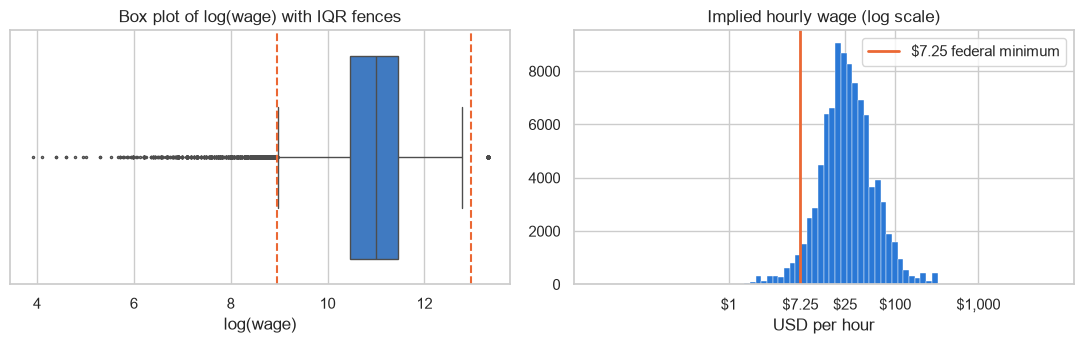

In [80]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
sns.boxplot(x=eda["log_wage"], ax=axes[0], color=BLUE, fliersize=1.5)
axes[0].axvline(low, color=ORANGE, ls="--", lw=1.5); axes[0].axvline(high, color=ORANGE, ls="--", lw=1.5)
axes[0].set_title("Box plot of log(wage) with IQR fences"); axes[0].set_xlabel("log(wage)")

axes[1].hist(np.log10(eda["hourly_wage"]), bins=80, color=BLUE, edgecolor="white", linewidth=0.3)
axes[1].axvline(np.log10(7.25), color=ORANGE, lw=2, label="$7.25 federal minimum")
axes[1].set_xticks(np.log10([1, 7.25, 25, 100, 1000]), ["$1", "$7.25", "$25", "$100", "$1,000"])
axes[1].set_title("Implied hourly wage (log scale)"); axes[1].set_xlabel("USD per hour"); axes[1].legend()
plt.tight_layout(); plt.show()

**Findings and decisions for Section 3:**
* **Low tail = data errors.** Some full-time, full-year workers report a few hundred dollars per year, i.e. an implied hourly rate of cents.
  This is impossible for an employee in Texas (minimum wage \$7.25), so it reflects reporting/recording errors.
  These rows will be removed using a documented threshold on the implied hourly wage.
* **High tail = real values, but censored.** About 1.4% of rows share the identical value \$601,000 — the Census **top-code** (the true
  wage is *at least* this). They are real high earners and will be kept; the cap is noted as a limitation.
* Applying the IQR rule blindly would also delete legitimate high earners (doctors, executives), which is why domain logic is used instead.

### 2.7 Correlation analysis
Different variable types need different correlation measures (Week 2):

* **Pearson** — linear relation between numerical variables;
* **Spearman** — monotonic relation, valid for **ordinal** variables such as education (`SCHL`);
* **Cramér's V** — association between two **nominal** variables (0 = none, 1 = perfect);
* **Point-biserial** — relation between a **binary** variable and a **numerical** target (e.g. sex and wage).

Correlations serve two purposes: finding the strongest predictors of wage, and detecting **multicollinearity** (predictors that duplicate each other).

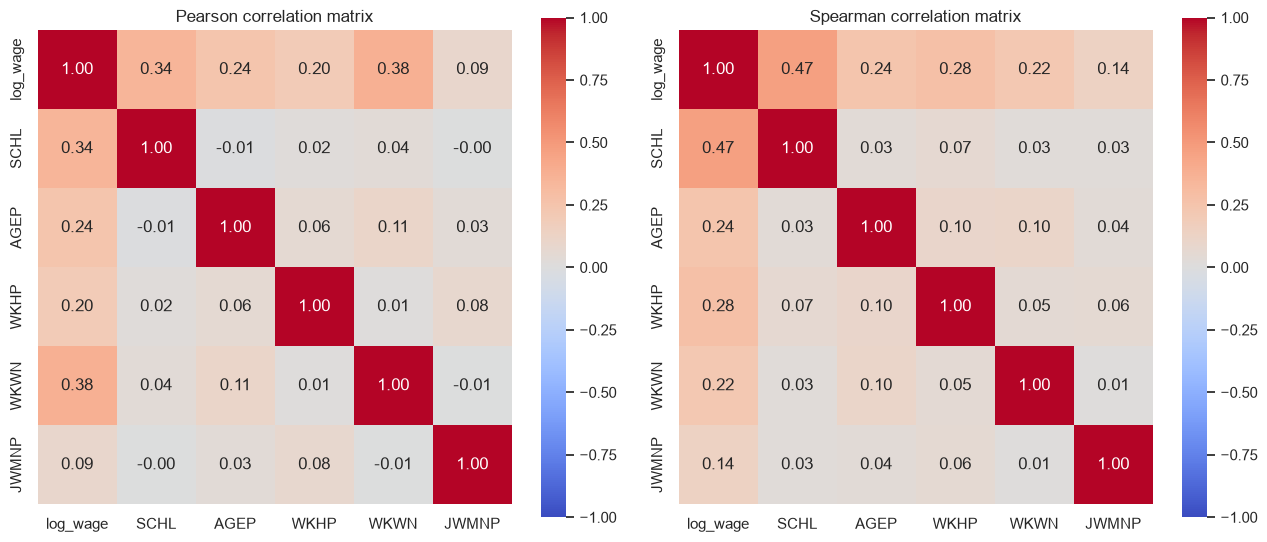

In [81]:
corr_cols = ["log_wage", "SCHL", "AGEP", "WKHP", "WKWN", "JWMNP"]
pearson  = eda[corr_cols].corr(method="pearson")
spearman = eda[corr_cols].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, mat, name in zip(axes, [pearson, spearman], ["Pearson", "Spearman"]):
    sns.heatmap(mat, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
    ax.set_title(f"{name} correlation matrix")
plt.tight_layout(); plt.show()

**Findings:**
* By **Spearman**, education (`SCHL`, ρ ≈ 0.47) is clearly the strongest numerical predictor of wage, followed by hours (0.28), age (0.24) and weeks worked (0.22).
* By **Pearson**, weeks worked looks strongest (r ≈ 0.38). This is driven by the low-wage tail: the few part-year workers with very small annual wages
  pull the linear correlation up. Spearman, which uses ranks, is robust to this — a good illustration of why both measures are reported.
* Education's Spearman (0.47) is much higher than its Pearson (0.34): the relation is **monotonic but not linear** (each extra level adds more money at the top).
* Predictors are almost uncorrelated with each other (all |r| ≤ 0.11), so there is **no multicollinearity** among numerical features.
* Commute time is only weakly related to wage.

In [82]:
def cramers_v(x, y):
    # Cramer's V from the chi-square statistic of the contingency table
    table = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    r, k = table.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

# Point-biserial correlation for the binary variables (1 = second category, 0 = first)
for col, value in [("sex", "Female"), ("nativity", "Foreign-born"), ("disability", "With disability")]:
    binary = (eda[col] == value).astype(int)
    r_pb, p_value = stats.pointbiserialr(binary, eda["log_wage"])
    print(f"{col:<11} ({value} = 1): r_pb = {r_pb:+.3f}")

cat_cols = ["occupation", "industry", "education", "employer", "sex", "marital",
            "race_eth", "nativity", "disability", "military", "transport"]

sex         (Female = 1): r_pb = -0.157
nativity    (Foreign-born = 1): r_pb = -0.033
disability  (With disability = 1): r_pb = -0.063


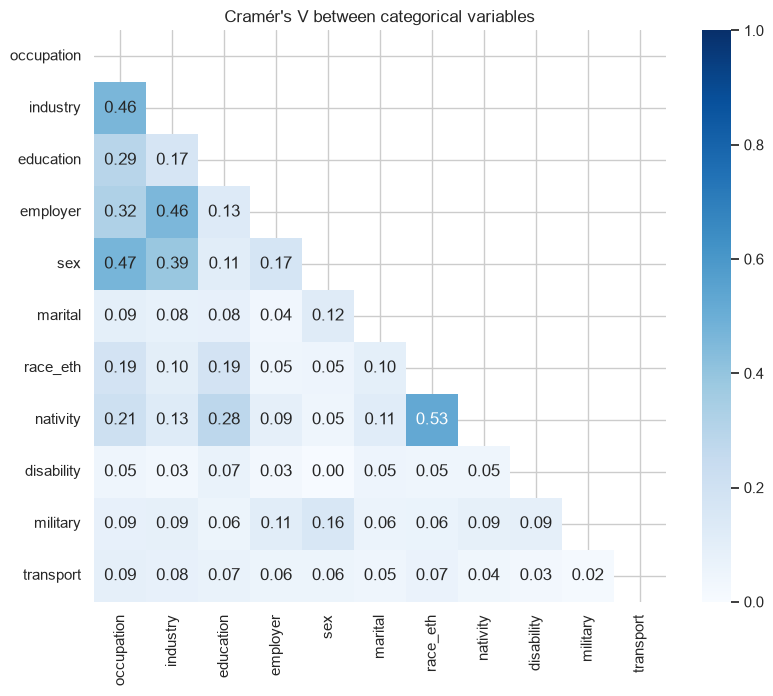

In [83]:
cv = pd.DataFrame(index=cat_cols, columns=cat_cols, dtype=float)
for a in cat_cols:
    for b in cat_cols:
        cv.loc[a, b] = 1.0 if a == b else cramers_v(eda[a].astype(str), eda[b].astype(str))

fig, ax = plt.subplots(figsize=(8.5, 7))
mask = np.triu(np.ones_like(cv, dtype=bool))      # show each pair once, hide the trivial diagonal
sns.heatmap(cv, mask=mask, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, square=True, ax=ax)
ax.set_title("Cramér's V between categorical variables")
plt.tight_layout(); plt.show()

**Findings:**
* **Point-biserial:** being female is associated with a lower log-wage (r_pb ≈ −0.16) — a weak but clear raw gap. Being foreign-born (−0.03)
  or having a disability (−0.06) shows almost no linear link on its own.
* For the multi-category variables, the **median wage tables (2.4)** and **box plots (2.8)** compare the groups directly: occupation and education
  separate wages the most, which matches labour-economics theory.
* The strongest associations between predictors are **race/ethnicity ↔ nativity** (V ≈ 0.53), **occupation ↔ sex** (0.47), **occupation ↔ industry** (0.46)
  and **employer type ↔ industry** (0.46). They are related but far from duplicates (V < 0.6), so all are kept. Tree-based models handle such overlap well,
  and the overlap is moderate enough not to distort the linear model.

### 2.8 Wages across key groups
Visual comparisons show *how* the strongest predictors relate to wages — including non-linear shapes that a single correlation number hides.

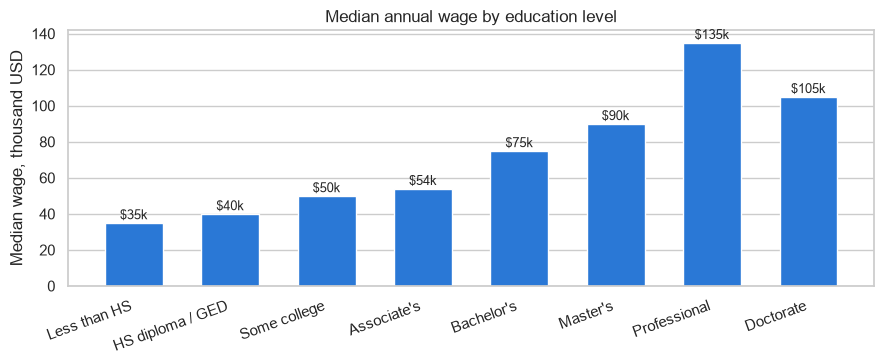

In [84]:
edu = eda.groupby("education", observed=True)["WAGP"].median() / 1000
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(edu.index.astype(str), edu.values, color=BLUE, width=0.6)
for x, v in enumerate(edu.values):
    ax.text(x, v + 2, f"${v:,.0f}k", ha="center", fontsize=9)
ax.set_ylabel("Median wage, thousand USD"); ax.grid(axis="x", visible=False)
ax.set_title("Median annual wage by education level")
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()

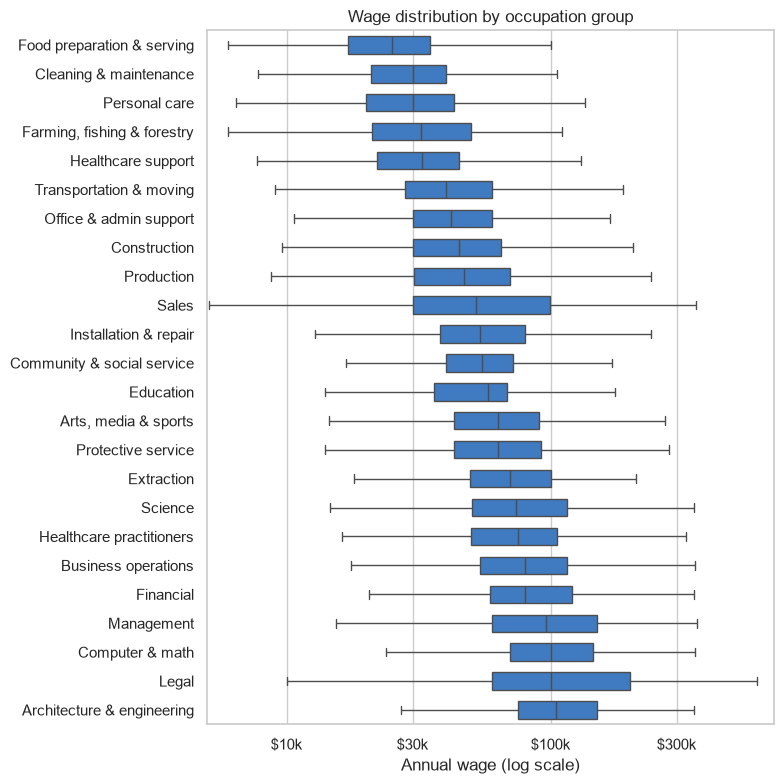

In [85]:
order = eda.groupby("occupation")["log_wage"].median().sort_values().index
fig, ax = plt.subplots(figsize=(8, 8))
sns.boxplot(data=eda, y="occupation", x="WAGP", order=order, color=BLUE, fliersize=0,
            ax=ax, log_scale=True, width=0.6)
ax.set_xlim(5_000, 700_000)
ax.set_xticks([10_000, 30_000, 100_000, 300_000], ["$10k", "$30k", "$100k", "$300k"])
ax.set_xlabel("Annual wage (log scale)"); ax.set_ylabel(""); ax.grid(axis="y", visible=False)
ax.set_title("Wage distribution by occupation group")
plt.tight_layout(); plt.show()

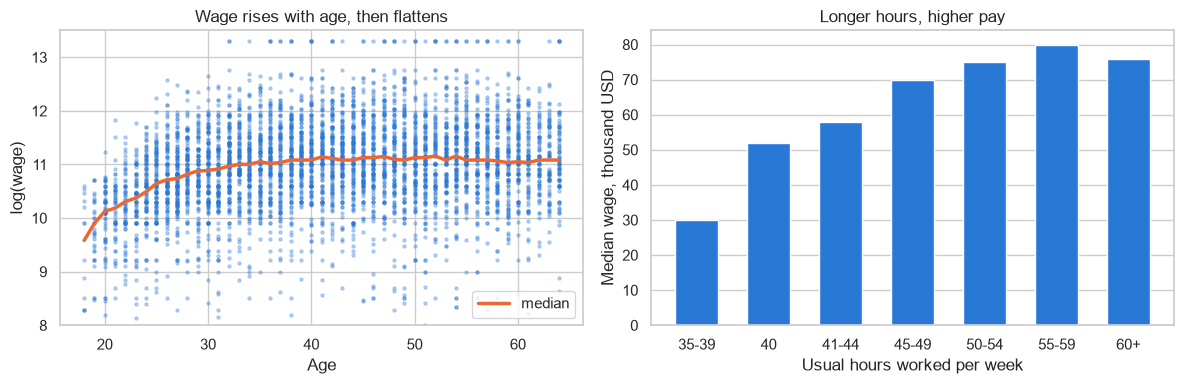

In [86]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# Age: scatter of a random 5,000-person sample + the median wage at each age
sample = eda.sample(5000, random_state=RANDOM_STATE)
axes[0].scatter(sample["AGEP"], sample["log_wage"], s=5, alpha=0.3, color=BLUE)
age_med = eda.groupby("AGEP")["log_wage"].median()
axes[0].plot(age_med.index, age_med.values, color=ORANGE, lw=2.5, label="median")
axes[0].set_ylim(8, 13.5); axes[0].set_xlabel("Age"); axes[0].set_ylabel("log(wage)")
axes[0].set_title("Wage rises with age, then flattens"); axes[0].legend(loc="lower right")

# Hours: median wage for each band of usual weekly hours
bands = pd.cut(eda["WKHP"], [34, 39, 40, 44, 49, 54, 59, 99],
               labels=["35-39", "40", "41-44", "45-49", "50-54", "55-59", "60+"])
hrs = eda.groupby(bands, observed=True)["WAGP"].median() / 1000
axes[1].bar(hrs.index.astype(str), hrs.values, color=BLUE, width=0.6)
axes[1].set_xlabel("Usual hours worked per week"); axes[1].set_ylabel("Median wage, thousand USD")
axes[1].set_title("Longer hours, higher pay"); axes[1].grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

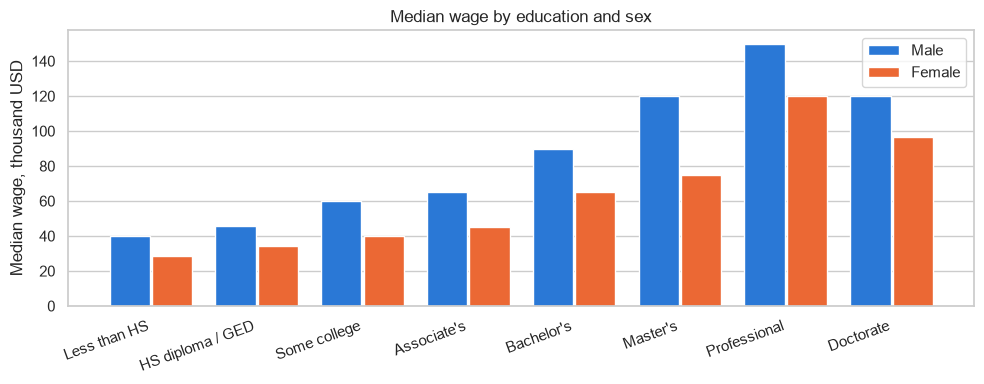

sex,Female,Male,female/male ratio
education,,,
Less than HS,28.50,40.00,0.71
HS diploma / GED,34.20,45.95,0.74
Some college,40.20,60.00,0.67
Associate's,45.00,65.00,0.69
Bachelor's,65.00,90.00,0.72
Master's,75.00,120.00,0.62
Professional,120.00,150.00,0.80
Doctorate,96.50,120.00,0.80


In [87]:
gap = (eda.groupby(["education", "sex"], observed=True)["WAGP"].median().unstack() / 1000)
x = np.arange(len(gap))
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(x - 0.2, gap["Male"], width=0.38, color=BLUE, label="Male")
ax.bar(x + 0.2, gap["Female"], width=0.38, color=ORANGE, label="Female")
ax.set_xticks(x, gap.index.astype(str), rotation=20, ha="right")
ax.set_ylabel("Median wage, thousand USD"); ax.grid(axis="x", visible=False); ax.legend()
ax.set_title("Median wage by education and sex")
plt.tight_layout(); plt.show()

gap["female/male ratio"] = gap["Female"] / gap["Male"]
gap.round(2)

**Findings:**
* The median wage rises with every education level up to professional degrees (\$135k); a bachelor's degree roughly **doubles** pay compared with no high-school diploma
  (\$75k vs \$35k). Doctorates (\$105k) earn less than professional degrees (doctors, lawyers), so education is ordinal but **not linear** in its effect.
* Occupation separates wages strongly (management, computing, engineering and healthcare practitioners at the top; food service and personal care at the bottom).
* The **age–wage profile is concave** (fast growth from 18 to about 35, then a plateau) — a linear model needs help to capture it
  (e.g. an age² feature), while tree models learn it automatically.
* Women earn less than men **at every education level** in this raw comparison (female/male median ratio 0.62–0.80). Part of the gap is explained by occupation and hours,
  which the models control for; this is discussed in the ethics section.

### 2.9 EDA summary → decisions for data preparation

| Finding | Decision in Section 3 |
|---|---|
| Categorical variables stored as numeric codes | decode and encode properly (ordinal for education, one-hot for nominal groups) |
| `ENG`, `JWMNP`, `JWTRNS` missing for structural reasons | fill with meaningful values, no row deletion |
| `FOD1P` missing for everyone without a degree, ~170 codes | drop — its information largely overlaps with education and occupation |
| Hundreds of detailed occupation/industry codes | group into major groups (high-cardinality reduction) |
| Target strongly right-skewed | model `log(WAGP)` |
| Implausibly low wages (implied hourly rate far below minimum wage) | remove as data errors with a documented threshold |
| Top-coded wages at \$601k | keep, note as a limitation |
| `ADJINC` constant factor | convert wages to 2024 dollars |
| Concave age profile | add `age²` feature for the linear model |
| Numerical features on different scales (age vs. hours vs. minutes) | standardise for Linear Regression and KNN |
| Weak correlations between predictors | no feature needs to be dropped for multicollinearity |

## 3. Data preparation
This section turns the EDA findings into a clean, model-ready dataset. Every step is justified by a finding from Section 2.
The order follows the lectures (Week 3): **fix errors → handle missing values → engineer features → split → encode and scale**.
Encoding and scaling are learned **only on the training set** (inside a `Pipeline`) to avoid data leakage.

In [88]:
data = df.copy()
print(f"Starting point: {len(data):,} rows")

Starting point: 92,513 rows


### 3.1 Correcting errors and standardising units
1. **Inflation adjustment.** ACS respondents are interviewed across the year and report income for the *previous* 12 months.
   The Census provides `ADJINC` to put all incomes into **2024 dollars**: `wage = WAGP × ADJINC / 1,000,000`.
2. **Impossible wages.** The implied hourly wage is `wage / (hours per week × weeks worked)`. The U.S. federal minimum wage is **\$7.25/hour**,
   so a full-time employee earning less than that is not legally possible — these values are reporting errors and are removed.

In [89]:
data["wage"] = data["WAGP"] * data["ADJINC"] / 1_000_000
print(f"ADJINC factor: {data['ADJINC'].iloc[0] / 1_000_000}")

data["hourly_wage"] = data["wage"] / (data["WKHP"] * data["WKWN"])
errors = data["hourly_wage"] < 7.25
print(f"Rows with implied hourly wage below $7.25: {errors.sum():,} ({errors.mean():.1%})")

data = data[~errors]
print(f"Rows after removing errors: {len(data):,}")

ADJINC factor: 1.01525
Rows with implied hourly wage below $7.25: 3,574 (3.9%)
Rows after removing errors: 88,939


**Target variable.** As shown in 2.5, wages are strongly right-skewed, so the models predict `log_wage = log(wage)`.

In [90]:
data["log_wage"] = np.log(data["wage"])
print(f"Skewness of wage:     {data['wage'].skew():.2f}")
print(f"Skewness of log_wage: {data['log_wage'].skew():.2f}")

Skewness of wage:     3.91
Skewness of log_wage: -0.14


After removing the errors, the log-wage is almost perfectly symmetric (skewness close to 0).

### 3.2 Handling missing values
All missing values are **structural** (Section 2.2), so they are filled with the value that the blank actually means — no imputation by mean or median is needed:

| Column | Blank means | Filled with |
|---|---|---|
| `ENG` (English ability, 1 = very well … 4 = not at all) | speaks only English | **0** — keeps the scale ordinal: 0 is the best English |
| `JWMNP` (commute minutes) | works from home or was not at work | **0** minutes |
| `JWTRNS` (means of transport) | not at work last week | used only to create the `work_from_home` flag below |

In [91]:
data["ENG"] = data["ENG"].fillna(0)
data["JWMNP"] = data["JWMNP"].fillna(0)

### 3.3 Feature engineering
New features are created from existing columns to give the models information in a more useful form:

| New feature | How | Why |
|---|---|---|
| `occupation` | ~520 `OCCP` codes → 25 major groups | too many rare codes; groups are meaningful and stable |
| `industry` | ~250 `INDP` codes → 17 sectors | same reason |
| `employer` | decode `COW` (private, non-profit, government) | readable categories |
| `marital` | decode `MAR` | readable categories |
| `age_sq` | `AGEP²` | lets the linear model capture the concave age profile (2.8) |
| `work_from_home` | 1 if `JWTRNS` = 11, else 0 | remote workers earn more on average (2.7) |

`hourly_wage` is **not** used as a feature: it is computed *from* the wage, so it would leak the answer.

In [92]:
data["occupation"] = codes.occupation_group(data["OCCP"])
data["industry"]   = codes.industry_sector(data["INDP"])
data["employer"]   = data["COW"].map(codes.COW)
data["marital"]    = data["MAR"].map(codes.MAR)
data["age_sq"]     = data["AGEP"] ** 2
data["work_from_home"] = (data["JWTRNS"].fillna(0) == 11).astype(int)   # blank = not at work, not WFH

print("Missing values in new columns:")
print(data[["occupation", "industry", "employer", "marital"]].isna().sum().to_string())

Missing values in new columns:
occupation    0
industry      0
employer      0
marital       0


### 3.4 Feature selection
The final feature set contains only variables that describe a person's **skills and job**. Protected characteristics
(sex, race/ethnicity, nativity, disability) are **deliberately excluded** from the model: a wage model used for salary benchmarking should not
set pay based on who someone is. These columns are kept aside to check the model's **fairness** in Section 5.

Other dropped columns: identifiers (`SERIALNO`, `SPORDER`), the weight `PWGTP`, the constant `ADJINC`, the raw codes replaced by groups
(`OCCP`, `INDP`, `COW`, `MAR`, `JWTRNS`), `FOD1P` (see 2.9), `MIL` (very weak link with wage, 2.7) and `PUMA` (217 small regions;
left out to keep the model simple — noted as a limitation).

In [93]:
NUM_FEATURES = ["AGEP", "age_sq", "SCHL", "WKHP", "WKWN", "JWMNP", "ENG", "work_from_home"]
CAT_FEATURES = ["occupation", "industry", "employer", "marital"]
TARGET = "log_wage"
FAIRNESS_COLS = ["SEX", "RAC1P", "HISP"]      # not used for training, only for the fairness check

model_data = data[NUM_FEATURES + CAT_FEATURES + [TARGET, "wage"] + FAIRNESS_COLS].reset_index(drop=True)
model_data[NUM_FEATURES] = model_data[NUM_FEATURES].astype(float)   # scikit-learn works with plain float columns
print(f"Model dataset: {model_data.shape[0]:,} rows, {len(NUM_FEATURES) + len(CAT_FEATURES)} features")
print(f"Missing values left: {model_data.isna().sum().sum()}")
model_data.head()

Model dataset: 88,939 rows, 12 features
Missing values left: 0


,AGEP,age_sq,SCHL,WKHP,WKWN,JWMNP,ENG,work_from_home,occupation,industry,employer,marital,log_wage,wage,SEX,RAC1P,HISP
0,43.00,"1,849.00",17.00,40.00,16.00,10.00,0.00,0.00,Management,"Arts, accommodation & food",Private for-profit,Never married,8.59,"5,380.82",2,2,1
1,36.00,"1,296.00",22.00,40.00,52.00,3.00,0.00,0.00,Personal care,"Finance, insurance & real estate",Private for-profit,Never married,10.76,"47,209.12",2,2,1
2,52.00,"2,704.00",16.00,40.00,52.00,0.00,0.00,1.00,Cleaning & maintenance,Health care & social assistance,Private for-profit,Divorced,10.32,"30,457.50",1,1,1
3,22.00,484.00,21.00,40.00,52.00,5.00,0.00,0.00,Office & admin support,"Finance, insurance & real estate",Private for-profit,Never married,10.47,"35,330.70",1,2,1
4,19.00,361.00,19.00,35.00,52.00,8.00,0.00,0.00,Education,Education,State government,Never married,9.63,"15,228.75",2,1,1


### 3.5 Train/test split
The data is split **before** any encoding or scaling is learned, so the test set stays completely unseen (no data leakage).

* **80% train / 20% test.** The test set (~18k people) is large enough for reliable evaluation.
* **No separate validation set:** hyperparameters will be tuned with **5-fold cross-validation on the training set** (Section 4),
  which uses the data more efficiently.
* **Stratified by wage level.** Wages have extreme values, so the target is cut into 10 equal-sized bins (`pd.qcut`) and the split keeps
  the same share of each bin in train and test (Week 5: stratified split for regression with extreme target values).

In [94]:
from sklearn.model_selection import train_test_split

wage_bins = pd.qcut(model_data[TARGET], q=10, labels=False)
train_df, test_df = train_test_split(model_data, test_size=0.2, random_state=RANDOM_STATE,
                                     stratify=wage_bins)

X_train, y_train = train_df[NUM_FEATURES + CAT_FEATURES], train_df[TARGET]
X_test,  y_test  = test_df[NUM_FEATURES + CAT_FEATURES],  test_df[TARGET]

print(f"Train: {len(X_train):,} rows   Test: {len(X_test):,} rows")
print(f"Median wage - train: ${train_df['wage'].median():,.0f}   test: ${test_df['wage'].median():,.0f}")

Train: 71,151 rows   Test: 17,788 rows
Median wage - train: $60,915   test: $60,915


The median wage is almost identical in both sets, confirming that the split is representative.

### 3.6 Encoding and scaling (preprocessing pipeline)
* **Categorical features → One-hot encoding.** Occupation, industry, employer type and marital status are nominal (no order),
  so each category becomes its own 0/1 column. `handle_unknown="ignore"` protects against a category that appears only in the test set.
* **Numerical features → StandardScaler** (z = (x − mean) / std). KNN measures **distances** between people, so a feature with large numbers (age² is in thousands)
  would dominate one with small numbers (`work_from_home` is 0/1) — scaling puts them on a comparable scale (Week 5: scaling is mandatory for KNN). Tree models do not need scaling, but it does not harm them,
  so one shared preprocessor is used for all models.
* `SCHL` (education 1–24) and `ENG` (0–4) are **ordinal**, so they stay as numbers and keep their natural order.

The preprocessor is a `ColumnTransformer` — the same pattern as Seminar 4. It is **fitted on the training data only**;
in Section 4 it is placed inside a `Pipeline` together with each model, so during cross-validation it is re-fitted on each training fold.

In [95]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), NUM_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_FEATURES),
])

# Fit on the training set only, then check the result
X_train_prepared = preprocessor.fit_transform(X_train)
print(f"Features before preprocessing: {X_train.shape[1]}")
print(f"Features after preprocessing:  {X_train_prepared.shape[1]} "
      f"({len(NUM_FEATURES)} scaled numerical + {X_train_prepared.shape[1] - len(NUM_FEATURES)} one-hot columns)")

Features before preprocessing: 12
Features after preprocessing:  58 (8 scaled numerical + 50 one-hot columns)


In [96]:
# Check: after scaling, numerical features in the training set have mean ~0 and std ~1
scaler = preprocessor.named_transformers_["num"]          # the fitted StandardScaler inside the preprocessor
scaled = pd.DataFrame(scaler.transform(X_train[NUM_FEATURES]), columns=NUM_FEATURES)
scaled.describe().loc[["mean", "std"]].round(2)

,AGEP,age_sq,SCHL,WKHP,WKWN,JWMNP,ENG,work_from_home
mean,-0.00,0.00,-0.00,0.00,-0.00,-0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


### 3.7 Data preparation summary

| Step | Result |
|---|---|
| Inflation adjustment | wages in 2024 dollars |
| Error removal | rows with hourly wage < \$7.25 removed (≈3.9%) |
| Target | `log_wage` (skewness ≈ 0) |
| Missing values | filled with their structural meaning; 0 missing values left |
| Feature engineering | 25 occupation groups, 17 industry sectors, `age_sq`, `work_from_home` |
| Features | 8 numerical/ordinal + 4 categorical; protected attributes excluded |
| Split | 80/20, stratified by wage decile |
| Preprocessing | StandardScaler + OneHotEncoder in a ColumnTransformer, fitted on train only |